<a href="https://colab.research.google.com/github/Ghule-vaibhavi/-machine-learning-model/blob/main/svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

support vector machine , flower
predication

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
df = pd.read_csv("/iris.csv")

print(df.head())
print(df.columns)
print(df.shape)


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')
(150, 5)


In [ ]:
print(df.isnull().sum())
print(df.info())
print(df.describe())


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.40

In [ ]:
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, gamma="scale")
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('svc', SVC(C=1))])

In [ ]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

print("Predicted species:", prediction[0])

Predicted species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


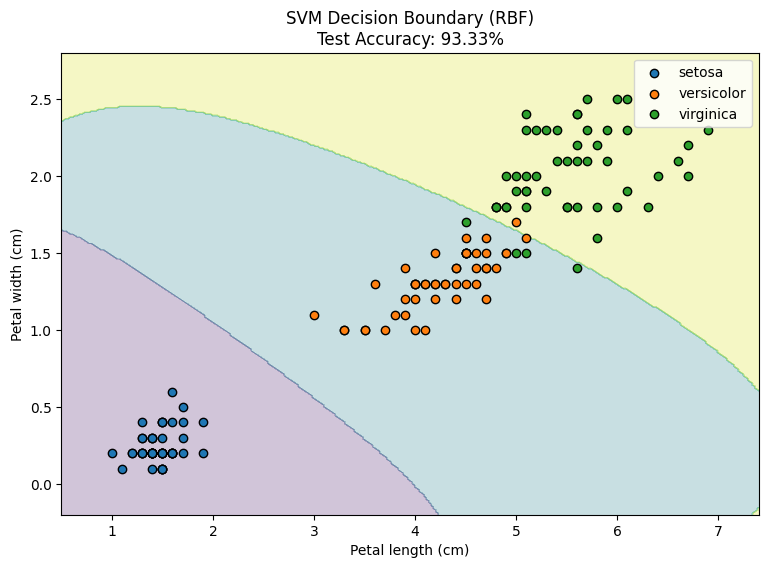

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("/iris.csv")

# Select only two features
X = df[["petal_length", "petal_width"]]
y = df["species"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model using two features
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1, gamma="scale")
)

model.fit(X_train, y_train)

# Create plotting grid
xx, yy = np.meshgrid(
    np.linspace(X["petal_length"].min() - 0.5,
                X["petal_length"].max() + 0.5, 300),
    np.linspace(X["petal_width"].min() - 0.3,
                X["petal_width"].max() + 0.3, 300)
)

grid = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

# Predict each point in the grid
Z = model.predict(grid)

encoder = LabelEncoder()
encoder.fit(y)
Z = encoder.transform(Z).reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25)

for species in sorted(y.unique()):
    subset = df[df["species"] == species]
    plt.scatter(
        subset["petal_length"],
        subset["petal_width"],
        label=species,
        edgecolors="black"
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title(
    f"SVM Decision Boundary (RBF)\n"
    f"Test Accuracy: {accuracy_score(y_test, model.predict(X_test)):.2%}"
)
plt.legend()
plt.show()